# LLM-A*-WW

LLM-A* with weighted waypoints. Evaluation on the 50x30 dataset (1000 samples) with the stored GPT-4o mini answers from our Table 1 reproduction.

In [1]:
# ---------------------------------------------------------------------------------------- configuration
RUN_ABLATION = True      # also run the ablation variants (about 2x longer)
LIMIT = None             # e.g. 50 for a quick test; None = all 1000 samples
QUERY_LLM = False        # False: stored GPT-4o mini answers (no API key needed)
                         # True:  ask the LLM again (needs OPENAI_API_KEY, about 3000 requests)
MODEL = "gpt-4o-mini"
N_PROCESSES = None       # parallel processes in Colab/Linux (None = all CPUs); Windows runs sequentially

## 1. Setup

In [2]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "github.com/leomueller5/llm_astar_max.git"


def is_project_dir(path):
    return (path / "llm-astar").is_dir() and (path / "table1_reproduction").is_dir()


def find_project_dir():
    candidates = [Path.cwd(), *Path.cwd().parents]
    if IN_COLAB:
        candidates = [Path("/content/llm_astar_max")] + candidates
    return next((c for c in candidates if is_project_dir(c)), None)


if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openai", "shapely"], check=True)

PROJECT_DIR = find_project_dir()
if PROJECT_DIR is None and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if is_project_dir(Path("/content/drive/MyDrive/llm_astar_max")):
        PROJECT_DIR = Path("/content/drive/MyDrive/llm_astar_max")
    else:
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        result = subprocess.run(["git", "clone", "-q", f"https://{token}@{REPO_URL}", "/content/llm_astar_max"],
                                capture_output=True)
        if result.returncode != 0:          # do not print the command: it contains the token
            raise RuntimeError("Cloning the repository failed. Check the Colab secret GITHUB_TOKEN.")
        PROJECT_DIR = Path("/content/llm_astar_max")
assert PROJECT_DIR is not None, "Project folder not found. Open the notebook inside the project folder."

CODE_DIR = PROJECT_DIR / "llm-astar"                         # original LLM-A* code (unchanged)
ANSWER_DIR = PROJECT_DIR / "table1_reproduction"             # stored GPT-4o mini answers
OUTPUT_DIR = PROJECT_DIR / "improving_llm_star" / "results"  # result files of this notebook
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(CODE_DIR))

In [3]:
import contextlib
import copy
import heapq
import io
import json
import math
import multiprocessing as mp
import time
import types
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# placeholders if transformers/torch are missing (only needed for LLaMA, not used here)
placeholders = []
for name in ("transformers", "torch"):
    try:
        __import__(name)
    except ImportError:
        sys.modules[name] = types.ModuleType(name)
        placeholders.append(name)

from llmastar.env.search import plotting
from llmastar.pather import AStar, LLMAStar
from llmastar.pather.llm_a_star.prompt import gpt_prompt
from llmastar.utils import list_parse

for name in placeholders:
    del sys.modules[name]

# switch off the animation of the original planners
plotting.Plotting.animation = lambda self, *args, **kwargs: None

PROMPTS = ["standard", "cot", "repe"]
PROMPT_NAMES = {"standard": "Few-Shot", "cot": "CoT", "repe": "RePE"}

## 2. Data and LLM answers

In [4]:
def load_samples(dataset_file):
    # one entry per start/goal pair: {"id": "<map>_<pair>", "query": {...}}
    with open(dataset_file, encoding="utf-8") as f:
        maps = json.load(f)
    samples = []
    for m in maps:
        for k, (start, goal, _text) in enumerate(m["start_goal"]):
            samples.append({
                "id": f"{m['id']}_{k}",
                "query": {"start": start, "goal": goal, "size": [51, 31],
                          "horizontal_barriers": m["horizontal_barriers"],
                          "vertical_barriers": m["vertical_barriers"],
                          "range_x": m["range_x"], "range_y": m["range_y"]},
            })
    return samples


def query_llm(samples, prompt_type, answer_file):
    # ask the LLM for every sample without a stored answer (same prompt as LLM-A*)
    from openai import OpenAI
    if not os.environ.get("OPENAI_API_KEY") and IN_COLAB:
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    client = OpenAI(max_retries=5)

    def ask(sample):
        q = sample["query"]
        prompt = gpt_prompt[prompt_type].format(start=q["start"], goal=q["goal"],
                                                horizontal_barriers=q["horizontal_barriers"],
                                                vertical_barriers=q["vertical_barriers"])
        r = client.chat.completions.create(model=MODEL, temperature=0, max_tokens=1000,
                                           messages=[{"role": "user", "content": prompt}])
        return sample["id"], r.choices[0].message.content or ""

    answers = json.load(open(answer_file, encoding="utf-8")) if answer_file.exists() else {}
    todo = [s for s in samples if s["id"] not in answers]
    with ThreadPoolExecutor(max_workers=8) as pool:
        answers.update(dict(pool.map(ask, todo)))
    json.dump(answers, open(answer_file, "w", encoding="utf-8"))
    return answers


samples = load_samples(CODE_DIR / "dataset" / "environment_50_30.json")[:LIMIT]
answers = {}
for pt in PROMPTS:
    if QUERY_LLM:
        answers[pt] = query_llm(samples, pt, OUTPUT_DIR / f"llm_responses_{pt}.json")
    else:
        answers[pt] = json.load(open(ANSWER_DIR / f"antworten_{pt}.json", encoding="utf-8"))
print(len(samples), "samples")

1000 samples


## 3. LLM-A*-WW

In [5]:
class LLMAStarWW(LLMAStar):
    """LLM-A* with weighted waypoints."""

    def __init__(self, llm="gpt", prompt="standard", weighting="los", switch_radius=3.0):
        super().__init__(llm=llm, prompt=prompt)
        assert weighting in ("los", "partial", "none")
        self.weighting = weighting
        self.switch_radius = switch_radius      # 0 = switching rule of LLM-A*
        self.waypoint_weights = []              # one weight per entry of target_list

    def _parse_waypoints(self, response):
        # LLM waypoints, filtered as in LLM-A*; unparsable answer -> no waypoints
        try:
            nodes = list_parse(response)
            return self._filter_valid_nodes([(node[0], node[1]) for node in nodes])
        except Exception:
            return []

    def _visible(self, p, q):
        # straight segment p-q touches no barrier and no map border
        return p == q or not self.is_collision(p, q)

    def _weight_waypoints(self, nodes):
        # returns targets [start, ..., goal] and one weight per target
        start, goal = self.s_start, self.s_goal
        waypoints = [n for n in nodes if n != start and n != goal]

        if self.weighting == "none":
            targets = [start] + waypoints + [goal]
            return targets, [1.0] * len(targets)

        if self.weighting == "partial":
            targets, weights = [start], [1.0]
            for k, t in enumerate(waypoints):
                prev = targets[-1]
                if self._visible(prev, goal):
                    break
                nxt = waypoints[k + 1] if k + 1 < len(waypoints) else goal
                weight = 0.5 * self._visible(prev, t) + 0.5 * self._visible(t, nxt)
                if weight > 0:
                    targets.append(t)
                    weights.append(weight)
            return targets + [goal], weights + [1.0]

        # "los": line-of-sight validation
        points = [start] + waypoints + [goal]
        targets, i = [start], 0
        while i < len(points) - 1:
            j = next((j for j in range(len(points) - 1, i, -1) if self._visible(points[i], points[j])), None)
            if j is None or j == len(points) - 1:     # chain broken, or goal visible
                break
            targets.append(points[j])
            i = j
        targets.append(goal)
        return targets, [1.0] * len(targets)

    def _initialize_llm_paths(self):
        query = self._generate_llm_query(list(self.s_start), list(self.s_goal))
        response = self.model.ask(prompt=query, max_tokens=1000)
        self.llm_waypoints = self._parse_waypoints(response)
        self.target_list, self.waypoint_weights = self._weight_waypoints(self.llm_waypoints)
        self.i = 1
        self.s_target = self.target_list[1]

    def heuristic(self, s):
        # h(s) + alpha_t * cost(t, s) + (1 - alpha_t) * h(s)
        h = math.hypot(self.s_goal[0] - s[0], self.s_goal[1] - s[1])
        to_target = math.hypot(self.s_target[0] - s[0], self.s_target[1] - s[1])
        alpha = self.waypoint_weights[min(self.i, len(self.waypoint_weights) - 1)]
        return h + alpha * to_target + (1.0 - alpha) * h

    def _target_reached(self, s, s_n):
        if s_n == self.s_target:                     # rule of LLM-A*
            return True
        return (self.switch_radius > 0 and
                math.hypot(self.s_target[0] - s[0], self.s_target[1] - s[1]) <= self.switch_radius)

    def searching(self, query, filepath="temp.png"):
        self.filepath = filepath
        self._initialize_parameters(self._parse_query(query))
        self._initialize_llm_paths()

        self.PARENT[self.s_start] = self.s_start
        self.g[self.s_start] = 0
        heapq.heappush(self.OPEN, (self.f_value(self.s_start), self.s_start))

        goal_reached = False
        while self.OPEN:
            _, s = heapq.heappop(self.OPEN)
            self.CLOSED.append(s)
            if s == self.s_goal:
                goal_reached = True
                break
            for s_n in self.get_neighbor(s):
                if self.s_target != self.s_goal and self._target_reached(s, s_n):
                    self._update_target()            # next waypoint
                    self._update_queue()             # re-score OPEN
                if s_n in self.CLOSED:
                    continue
                new_cost = self.g[s] + self.cost(s, s_n)
                if s_n not in self.g:
                    self.g[s_n] = math.inf
                if new_cost < self.g[s_n]:
                    self.g[s_n] = new_cost
                    self.PARENT[s_n] = s
                    heapq.heappush(self.OPEN, (self.f_value(s_n), s_n))

        path = self.extract_path(self.PARENT) if goal_reached else []
        length = (sum(self._euclidean_distance(path[k], path[k + 1]) for k in range(len(path) - 1))
                  if path else math.inf)
        return {"operation": len(self.CLOSED), "storage": len(self.g), "length": length,
                "llm_output": self.target_list}

## 4. Baselines and experiment

In [6]:
ABLATION = {
    "WW: weights only (partial)": dict(weighting="partial", switch_radius=0.0),
    "WW: switching only": dict(weighting="none", switch_radius=3.0),
    "WW: line-of-sight weights only": dict(weighting="los", switch_radius=0.0),
}


class CachedAnswer:
    # replaces the LLM client and returns a stored answer
    def __init__(self, answer):
        self.answer = answer

    def ask(self, *args, **kwargs):
        return self.answer


class DynamicWAStar(AStar):
    def weight(self):
        return max(1.0, 2.0 * 0.99 ** len(self.CLOSED))

    def f_value(self, s):
        return self.g[s] + self.weight() * self.heuristic(s)

    def get_neighbor(self, s):
        self.OPEN = [(self.f_value(n), n) for _, n in self.OPEN]
        heapq.heapify(self.OPEN)
        return super().get_neighbor(s)


def quiet(func):
    with contextlib.redirect_stdout(io.StringIO()):
        return func()


def timed(make_planner, query, answer=None):
    # (operation, storage, length, seconds) of one planner on one sample
    def run(text):
        planner = make_planner()
        if text is not None:
            planner.model = CachedAnswer(text)
        return quiet(lambda: planner.searching(query=copy.deepcopy(query)))
    t0 = time.perf_counter()
    try:
        r = run(answer)
    except Exception:
        r = run("")                       # original parser fails -> no waypoints
    return r["operation"], r["storage"], r["length"], time.perf_counter() - t0


def run_sample(job):
    sample, sample_answers, ablation = job
    q = sample["query"]
    row = {"id": sample["id"],
           "A*": timed(AStar, q),
           "Dynamic WA*": timed(DynamicWAStar, q),
           "Static WA* (w=2)": timed(lambda: LLMAStar(llm="gpt", prompt="standard"), q, "")}
    for pt in PROMPTS:
        a = sample_answers[pt]
        row[f"LLM-A*|{pt}"] = timed(lambda: LLMAStar(llm="gpt", prompt=pt), q, a)
        row[f"LLM-A*-WW|{pt}"] = timed(lambda: LLMAStarWW(llm="gpt", prompt=pt), q, a)
        if ablation:
            for name, kw in ABLATION.items():
                row[f"{name}|{pt}"] = timed(lambda: LLMAStarWW(llm="gpt", prompt=pt, **kw), q, a)
    return row


jobs = [(s, {pt: answers[pt][s["id"]] for pt in PROMPTS}, RUN_ABLATION) for s in samples]
t0 = time.time()
rows = []
if "fork" in mp.get_all_start_methods():          # Colab / Linux: parallel
    with mp.get_context("fork").Pool(N_PROCESSES) as pool:
        for i, row in enumerate(pool.imap(run_sample, jobs, chunksize=4), 1):
            rows.append(row)
            if i % 100 == 0:
                print(f"{i} / {len(jobs)} samples ({time.time() - t0:.0f} s)")
else:                                             # Windows: sequential
    for i, job in enumerate(jobs, 1):
        rows.append(run_sample(job))
        if i % 100 == 0:
            print(f"{i} / {len(jobs)} samples ({time.time() - t0:.0f} s)")
json.dump(rows, open(OUTPUT_DIR / "per_sample_results_ww.json", "w", encoding="utf-8"))

100 / 1000 samples (209 s)


200 / 1000 samples (362 s)


300 / 1000 samples (521 s)


400 / 1000 samples (775 s)


500 / 1000 samples (972 s)


600 / 1000 samples (1116 s)


700 / 1000 samples (1348 s)


800 / 1000 samples (1503 s)


900 / 1000 samples (1629 s)


1000 / 1000 samples (1769 s)


## 5. Results

In [7]:
def ratio_stats(ratios):
    r = np.asarray(ratios, dtype=float)
    r = r[np.isfinite(r) & (r > 0)]
    n, logs = len(r), np.log(r)
    half = stats.t.ppf(0.975, n - 1) * logs.std(ddof=1) / np.sqrt(n)
    return dict(mean=100 * np.exp(logs.mean()), ci_low=100 * np.exp(logs.mean() - half),
                ci_high=100 * np.exp(logs.mean() + half), sd=100 * r.std(ddof=1), n=n)


def share_stats(flags):
    x = np.asarray(flags, dtype=bool)
    n, p, z = len(x), x.mean(), stats.norm.ppf(0.975)
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return dict(mean=100 * p, ci_low=100 * (centre - half), ci_high=100 * (centre + half),
                sd=100 * x.std(ddof=1), n=n)


a = np.array([r["A*"] for r in rows], dtype=float)   # columns: operation, storage, length, time
long, compact = [], []
for key in [k for k in rows[0] if k not in ("id", "A*")]:
    method, _, pt = key.partition("|")
    prompt = PROMPT_NAMES.get(pt, "-")
    m = np.array([r[key] for r in rows], dtype=float)
    metrics = {"OR": ratio_stats(m[:, 0] / a[:, 0]),
               "SR": ratio_stats(m[:, 1] / a[:, 1]),
               "RL": ratio_stats(m[:, 2] / a[:, 2]),
               "VPR": share_stats(np.isfinite(m[:, 2])),
               "Worse than A* (OR > 100 %)": share_stats(m[:, 0] > a[:, 0]),
               "Time": ratio_stats(m[:, 3] / a[:, 3])}
    row = {"Method": method, "Prompt": prompt}
    for name, st in metrics.items():
        long.append({"Method": method, "Prompt": prompt, "Metric": name, **st})
        row[name] = f"{st['mean']:.2f} [{st['ci_low']:.2f}, {st['ci_high']:.2f}]"
    compact.append(row)

long, compact = pd.DataFrame(long), pd.DataFrame(compact)
long.round(2).to_csv(OUTPUT_DIR / "ww_with_statistics.csv", index=False)
compact.to_csv(OUTPUT_DIR / "ww_with_ci.csv", index=False)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
main_methods = ["Dynamic WA*", "Static WA* (w=2)", "LLM-A*", "LLM-A*-WW"]
print("Main comparison:")
print(compact[compact.Method.isin(main_methods)].to_string(index=False))
if RUN_ABLATION:
    print("\nAblation:")
    print(compact[~compact.Method.isin(main_methods[:2])].to_string(index=False))

Main comparison:
          Method   Prompt                   OR                   SR                      RL                    VPR Worse than A* (OR > 100 %)                 Time
     Dynamic WA*        - 60.90 [57.73, 64.25] 78.52 [76.77, 80.32] 100.24 [100.18, 100.31] 100.00 [99.62, 100.00]       60.40 [57.33, 63.39] 78.26 [74.72, 81.97]
Static WA* (w=2)        - 34.32 [32.74, 35.97] 56.23 [55.08, 57.41] 102.02 [101.77, 102.26] 100.00 [99.62, 100.00]          5.30 [4.07, 6.87] 42.32 [40.82, 43.88]
          LLM-A* Few-Shot 46.09 [43.71, 48.59] 65.40 [63.68, 67.17] 102.74 [102.49, 102.98] 100.00 [99.62, 100.00]       17.30 [15.08, 19.77] 55.28 [52.97, 57.70]
       LLM-A*-WW Few-Shot 34.75 [33.17, 36.41] 56.59 [55.43, 57.77] 102.13 [101.89, 102.37] 100.00 [99.62, 100.00]          5.60 [4.34, 7.20] 43.69 [42.16, 45.27]
          LLM-A*      CoT 47.61 [45.17, 50.19] 66.24 [64.47, 68.06] 102.61 [102.35, 102.87] 100.00 [99.62, 100.00]       17.20 [14.99, 19.66] 56.44 [54.08, 58.90]
     

## 6. Examples

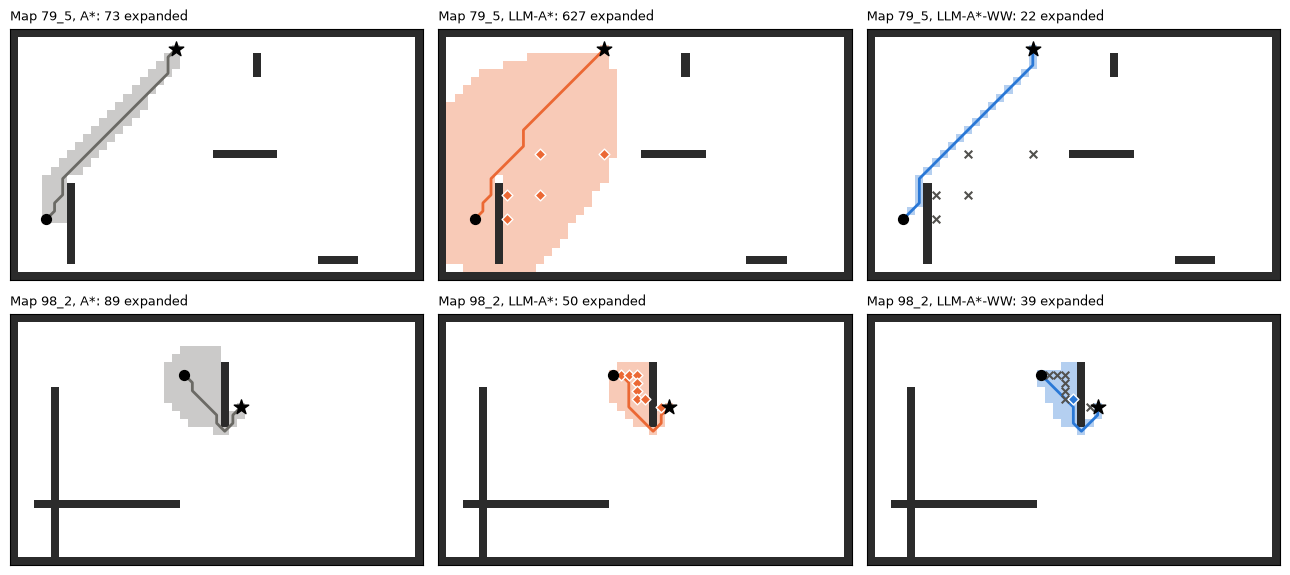

In [8]:
def pick_examples(rows, pt="standard"):
    # 1. largest gain of WW among samples where LLM-A* is worse than A*; 2. typical (median) gain
    llm_key, ww_key = f"LLM-A*|{pt}", f"LLM-A*-WW|{pt}"
    ratio = {r["id"]: r[llm_key][0] / r[ww_key][0] for r in rows}
    bad = [r["id"] for r in rows if r[llm_key][0] > r["A*"][0]] or list(ratio)   # fallback for small LIMIT
    worst = max(bad, key=lambda i: ratio[i])
    differing = [i for i in ratio if abs(ratio[i] - 1) > 0.05 and i != worst]
    median = np.median([ratio[i] for i in differing])
    return [worst, min(differing, key=lambda i: abs(ratio[i] - median))]


def search_data(make, query, answer=None):
    # run one planner and keep what is needed for drawing
    planner = make()
    if answer is not None:
        planner.model = CachedAnswer(answer)
    quiet(lambda: planner.searching(query=copy.deepcopy(query)))
    data = {"operation": len(planner.CLOSED),
            "closed": [list(c) for c in dict.fromkeys(planner.CLOSED)],
            "path": [list(p) for p in planner.extract_path(planner.PARENT)]}
    if answer is not None:
        used = planner.target_list[1:-1]
        data["waypoints_used"] = [list(p) for p in used]
        data["waypoints_dropped"] = [list(p) for p in getattr(planner, "llm_waypoints", [])
                                     if p not in used and p not in (planner.s_start, planner.s_goal)]
    return data, planner


by_id = {s["id"]: s for s in samples}
examples = {}
for sample_id in pick_examples(rows):
    q, a = by_id[sample_id]["query"], answers["standard"][sample_id]
    astar_data, planner = search_data(AStar, q)
    examples[sample_id] = {
        "width": planner.Env.x_range, "height": planner.Env.y_range,
        "obstacles": sorted([list(o) for o in planner.Env.obs]),
        "start": list(planner.s_start), "goal": list(planner.s_goal),
        "A*": astar_data,
        "LLM-A*": search_data(lambda: LLMAStar(llm="gpt", prompt="standard"), q, a)[0],
        "LLM-A*-WW": search_data(lambda: LLMAStarWW(llm="gpt", prompt="standard"), q, a)[0]}
json.dump(examples, open(OUTPUT_DIR / "example_searches.json", "w", encoding="utf-8"))


def draw(ax, ex, method, colour, title):
    grid = np.ones((ex["height"], ex["width"], 3))
    for x, y in ex[method]["closed"]:
        grid[y, x] = np.array(plt.matplotlib.colors.to_rgb(colour)) * 0.35 + 0.65
    for x, y in ex["obstacles"]:
        grid[y, x] = 0.17
    ax.imshow(grid, origin="lower", interpolation="nearest")
    path = ex[method]["path"]
    ax.plot([p[0] for p in path], [p[1] for p in path], color=colour, lw=2)
    if ex[method].get("waypoints_dropped"):
        ax.scatter(*zip(*ex[method]["waypoints_dropped"]), marker="x", s=30, color="#52514e", zorder=3)
    if ex[method].get("waypoints_used"):
        ax.scatter(*zip(*ex[method]["waypoints_used"]), marker="D", s=30, color=colour,
                   edgecolor="white", zorder=3)
    ax.scatter(*ex["start"], s=50, color="black", zorder=4)
    ax.scatter(*ex["goal"], marker="*", s=120, color="black", zorder=4)
    ax.set_title(title, loc="left", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(len(examples), 3, figsize=(13, 3.0 * len(examples)))
for row_axes, (sample_id, ex) in zip(axes, examples.items()):
    for ax, (method, colour) in zip(row_axes, [("A*", "#6b6a65"), ("LLM-A*", "#eb6834"),
                                               ("LLM-A*-WW", "#2a78d6")]):
        draw(ax, ex, method, colour, f"Map {sample_id}, {method}: {ex[method]['operation']} expanded")
plt.tight_layout()
plt.show()

## 7. Output files

Saved in `improving_llm_star/results/`. Figures for the report: `python improving_llm_star/make_figures.py`.